<p align="center"><img src="logo_ups.png" alt="Universidad Politécnica Salesiana Ecuador" width="520"></p>

# Práctica 2: Operaciones y preprocesamiento de imágenes

**Universidad:** Universidad Politécnica Salesiana

**Carrera:** Computación 
<br>
**Materia:** Visión por Computador  
<br>
**Estudiante:** Angel Lucero, Fernadno Mejia, Erick Salinas
<br>
**Docente:** Ing. Remigio Hurtado

## Introducción

En esta práctica se aplican operaciones de procesamiento digital a cuatro fotografías del dataset propio: dos vistas de un producto de leche condensada y dos de Milo. Se estudian ajustes de contraste, convolución y filtros, operaciones morfológicas, detección de bordes y la relación entre filtros clásicos y una capa convolucional. El propósito es observar cómo estas técnicas preparan y resaltan información visual relevante en envases reales.



## 1. Operaciones sobre puntos: contraste e histograma

Una operación sobre puntos transforma cada píxel de forma independiente. En este apartado se compara la normalización min-max con la ecualización global y CLAHE. Primero se simula una subexposición en escala de grises para observar cómo la normalización expande el rango; después se comparan ecualización y CLAHE sobre una vista propia. En los gráficos, el histograma muestra cuántos píxeles hay en cada intensidad y la CDF muestra la acumulación de esas frecuencias.


### Datos de trabajo y preparación

Se seleccionaron cuatro archivos del dataset propio: dos vistas de leche condensada y dos de Milo. La celda siguiente busca las imágenes desde la raíz del repositorio o desde la carpeta `practica2`, las convierte a RGB para mostrarlas correctamente y presenta la muestra antes del procesamiento. Los nombres de clase son provisionales, de acuerdo con el registro del proyecto.


In [1]:
from pathlib import Path
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Librerias importadas correctamente")

Librerias importadas correctamente


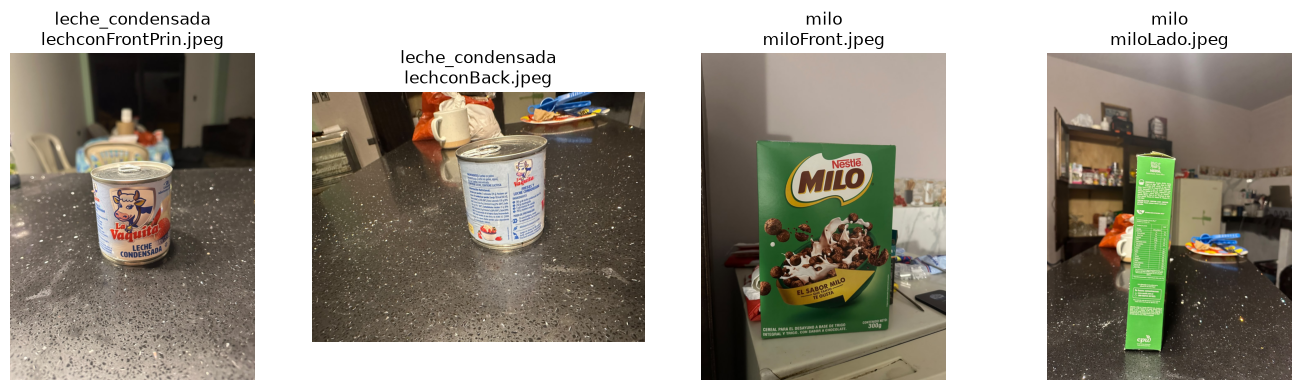

In [2]:
# Se puede abrir desde la raiz del repositorio o desde practica2/.
RAIZ=Path.cwd()
if (RAIZ/"practica2").exists(): RUTA_DATASET=RAIZ/"Proyecto Integrador P1"/"data"/"propio"/"originales"
elif (RAIZ.parent/"Proyecto Integrador P1").exists(): RUTA_DATASET=RAIZ.parent/"Proyecto Integrador P1"/"data"/"propio"/"originales"
else: raise FileNotFoundError("Abre el cuaderno desde la raiz del repositorio o desde practica2/")
archivos=["lechconFrontPrin.jpeg","lechconBack.jpeg","miloFront.jpeg","miloLado.jpeg"]
clases_por_archivo={"lechconFrontPrin.jpeg":"leche_condensada","lechconBack.jpeg":"leche_condensada","miloFront.jpeg":"milo","miloLado.jpeg":"milo"}
imagenes_rgb={}
for archivo in archivos:
    bgr=cv2.imread(str(RUTA_DATASET/archivo))
    if bgr is None: raise FileNotFoundError(f"No se encontro: {RUTA_DATASET/archivo}")
    imagenes_rgb[archivo]=cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB)
imagen_rgb=imagenes_rgb[archivos[0]]
imagen=cv2.cvtColor(imagen_rgb,cv2.COLOR_RGB2BGR)
fig,ejes=plt.subplots(1,4,figsize=(14,4))
for eje,archivo in zip(ejes,archivos): eje.imshow(imagenes_rgb[archivo]); eje.set_title(f"{clases_por_archivo[archivo]}\n{archivo}"); eje.axis("off")
plt.tight_layout(); plt.show()


### Funciones de visualización

Se definen dos funciones auxiliares: `histograma` presenta la frecuencia de cada intensidad de gris y `mostrar` organiza imágenes para comparar resultados. Se reutilizan en las operaciones siguientes para que las diferencias sean fáciles de observar.


In [3]:
def histograma(eje, gris, titulo, color="#42A5F5"):
    eje.hist(gris.ravel(), bins=256, range=(0, 256), color=color)
    eje.set_title(titulo)
    eje.set_xlim(0, 255)
    eje.set_yticks([])
    
def mostrar(imagenes, titulos, cmap=None, ancho=4):
    fig, ejes = plt.subplots(1, len(imagenes), figsize=(ancho * len(imagenes), ancho))
    for eje, im, t in zip(np.atleast_1d(ejes), imagenes, titulos):
        if im.ndim == 2:
            fijo = im.dtype == np.uint8
            eje.imshow(im, cmap=cmap or "gray", vmin=0 if fijo else None, vmax=255 if fijo else None)
        else:
            eje.imshow(im)
        eje.set_title(t)
        eje.axis("off")
    plt.tight_layout()
    plt.show()


### 1.1 Normalización del contraste

Se convierte la imagen seleccionada a escala de grises y se reduce artificialmente su brillo para simular una toma subexpuesta. La normalización min-max transforma el mínimo y máximo observados al rango 0–255. El histograma permite comprobar que las intensidades, antes agrupadas en una zona estrecha, ocupan un rango mayor. Esta simulación ayuda a explicar la operación; no sustituye una captura realmente oscura.


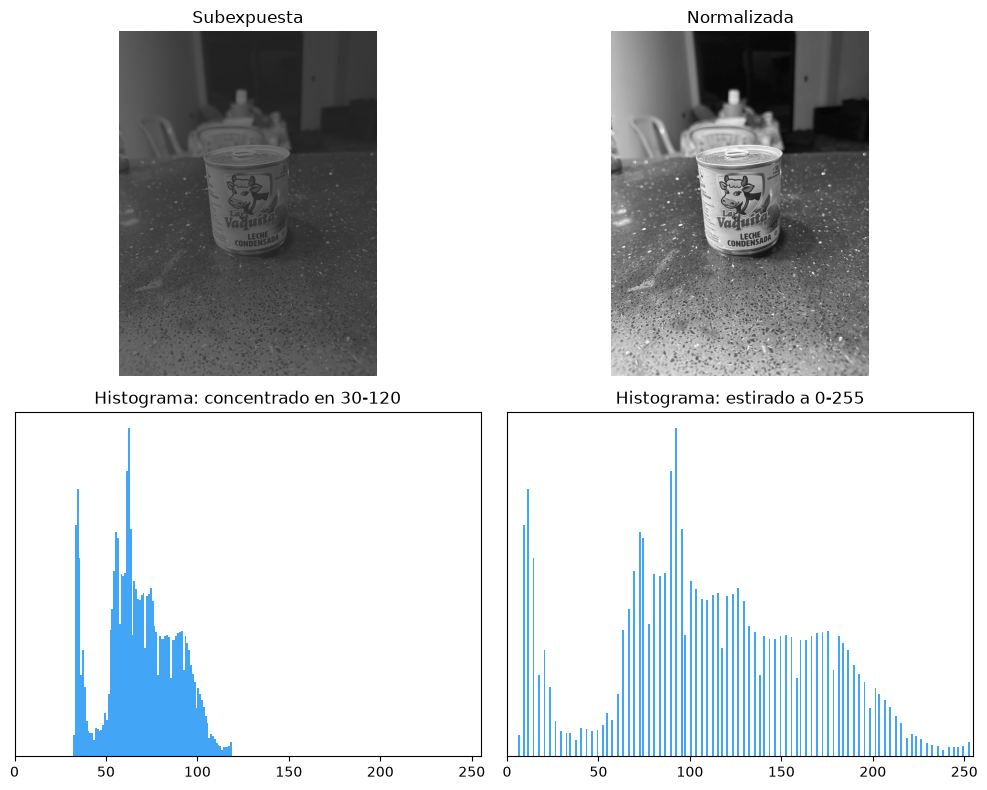

In [4]:
np.random.seed(42)
gris = cv2.cvtColor(imagen_rgb,cv2.COLOR_RGB2GRAY)
subexpuesta = (gris * 0.35 + 30).astype(np.uint8)

minimo, maximo = int(subexpuesta.min()), int(subexpuesta.max())
manual = ((subexpuesta.astype(float) - minimo) / (maximo - minimo) * 255).astype(np.uint8)
opencv = cv2.normalize(subexpuesta, None, 0, 255, cv2.NORM_MINMAX)

fig, ejes = plt.subplots(2, 2, figsize=(10, 8))
ejes[0, 0].imshow(subexpuesta, cmap="gray", vmin=0, vmax=255)
ejes[0, 0].set_title("Subexpuesta")
ejes[0, 1].imshow(opencv, cmap="gray", vmin=0, vmax=255)
ejes[0, 1].set_title("Normalizada")
histograma(ejes[1, 0], subexpuesta, "Histograma: concentrado en 30-120")
histograma(ejes[1, 1], opencv, "Histograma: estirado a 0-255")
for e in ejes[0]:
    e.axis("off")
plt.tight_layout()
plt.show()


### 1.2 Ecualización global y CLAHE

La ecualización global usa la distribución acumulada (CDF) para redistribuir intensidades en toda la imagen. La primera parte implementa esa transformación manualmente y la compara con OpenCV; una diferencia máxima de cero indica que ambas producen el mismo resultado. CLAHE aplica la ecualización por regiones y limita el contraste local para reducir la amplificación excesiva. Las filas muestran la imagen, su histograma y su CDF para comparar cómo se distribuyen los tonos.


Diferencia máxima ecualización manual vs cv2.equalizeHist: 0


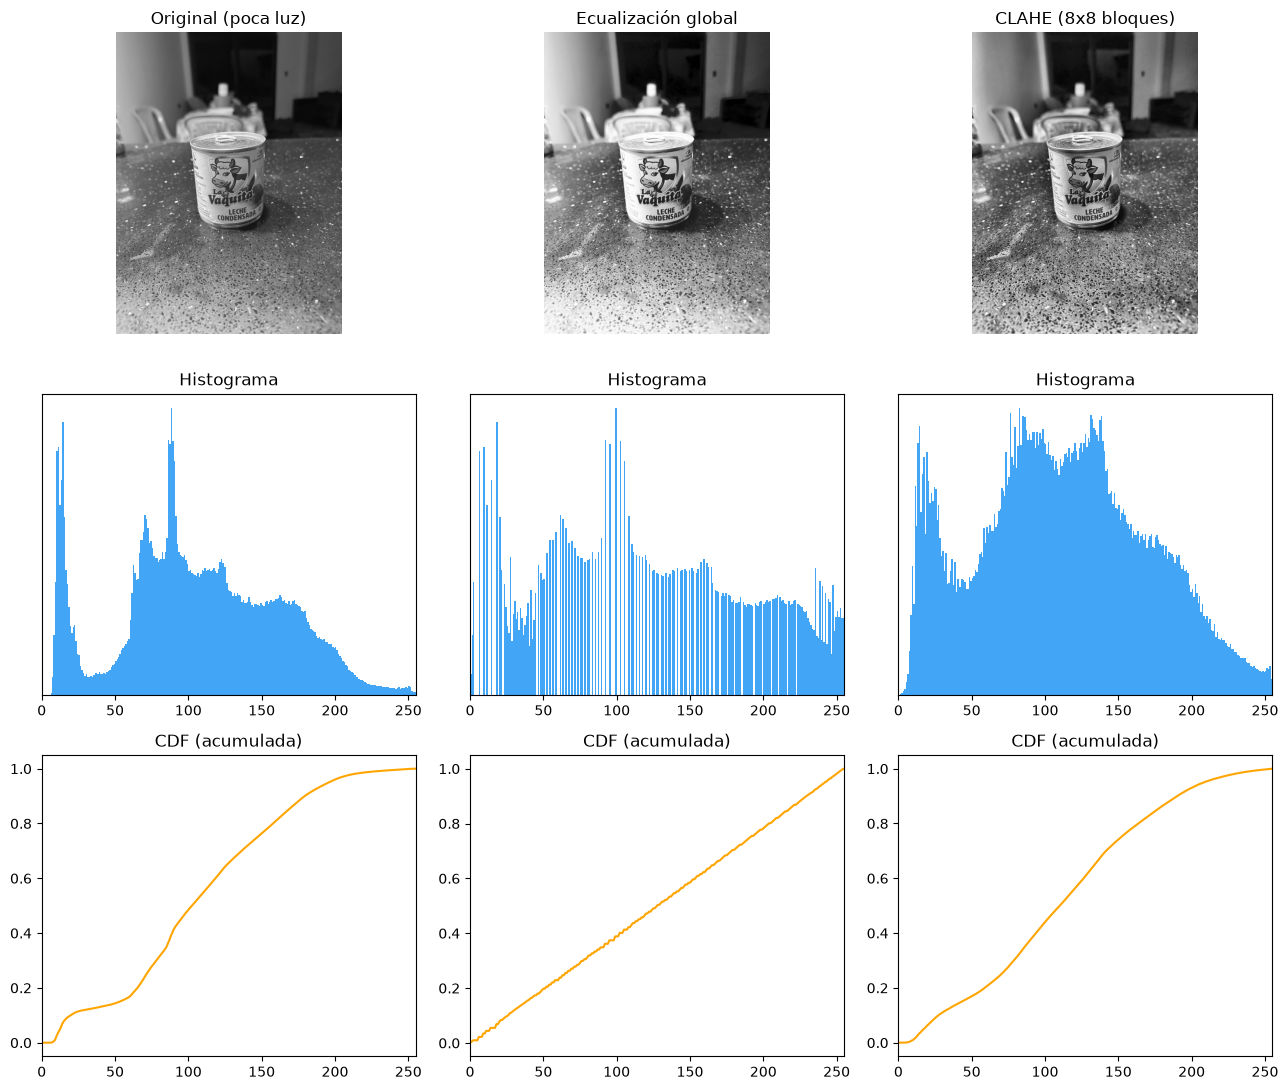

Original    media =  106.9   desviación estándar (contraste) =  54.2
Ecualizada  media =  128.3   desviación estándar (contraste) =  73.4
CLAHE       media =  111.6   desviación estándar (contraste) =  57.6


In [5]:
gris_oscura = cv2.cvtColor(imagen, cv2.COLOR_RGB2GRAY)

hist = np.bincount(gris_oscura.ravel(), minlength=256)
cdf = hist.cumsum()
cdf_min = cdf[cdf > 0][0]
tabla = np.round((cdf - cdf_min) / (gris_oscura.size - cdf_min) * 255).clip(0, 255).astype(np.uint8)
ecualizada_manual = tabla[gris_oscura]  # cada nivel v se reemplaza por tabla[v]
ecualizada = cv2.equalizeHist(gris_oscura)
print("Diferencia máxima ecualización manual vs cv2.equalizeHist:",
    np.abs(ecualizada_manual.astype(int) - ecualizada.astype(int)).max())

# CLAHE: ecualización por bloques con límite de contraste (evita amplificar ruido)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gris_oscura)

fig, ejes = plt.subplots(3, 3, figsize=(13, 11))
for c, (img, nombre) in enumerate([(gris_oscura, "Original (poca luz)"),
                                (ecualizada, "Ecualización global"), (clahe, "CLAHE (8x8 bloques)")]):
    ejes[0, c].imshow(img, cmap="gray", vmin=0, vmax=255)
    ejes[0, c].set_title(nombre)
    ejes[0, c].axis("off")
    histograma(ejes[1, c], img, "Histograma")
    cdf_img = np.bincount(img.ravel(), minlength=256).cumsum()
    ejes[2, c].plot(cdf_img / cdf_img[-1], color="orange")
    ejes[2, c].set_title("CDF (acumulada)")
    ejes[2, c].set_xlim(0, 255)
plt.tight_layout()
plt.show()
for nombre, img in [("Original", gris_oscura), ("Ecualizada", ecualizada), ("CLAHE", clahe)]:
    print(f"{nombre:<11} media = {img.mean():6.1f}   desviación estándar (contraste) = {img.std():5.1f}")

### 1.3 Mejora de una imagen a color

La ecualización independiente de R, G y B puede cambiar el balance de color y teñir el empaque. Para evitarlo, se convierte la imagen a HSV y se aplica CLAHE solo al canal V (brillo); H y S se mantienen. La comparación visual permite verificar si mejora la iluminación sin alterar de forma marcada los colores del producto.


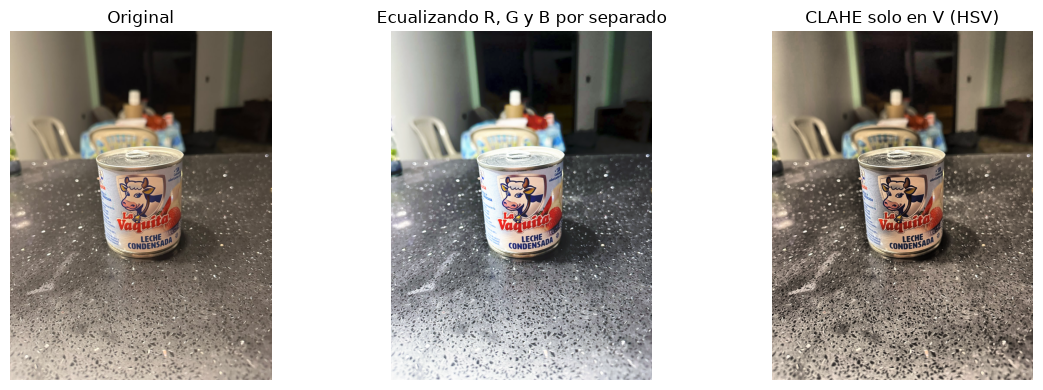

In [6]:
hsv = cv2.cvtColor(imagen_rgb, cv2.COLOR_RGB2HSV)
hsv_v = hsv.copy()
hsv_v[..., 2] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(hsv[..., 2])
color_v = cv2.cvtColor(hsv_v, cv2.COLOR_HSV2RGB)
por_canal = np.dstack([cv2.equalizeHist(imagen_rgb[..., i]) for i in range(3)])
mostrar([imagen_rgb, por_canal, color_v],
        ["Original", "Ecualizando R, G y B por separado", "CLAHE solo en V (HSV)"])

### Conclusiones y recomendaciones

La normalización y la ecualización mejoran el contraste; CLAHE aplicado al brillo V ayuda a conservar el color. Comparar con la imagen original y evitar ajustes que amplifiquen ruido o cambien la apariencia del producto.


## 2. Operaciones sobre grupos de puntos: convolución y filtros

Se estudia cómo un kernel combina los valores de los píxeles vecinos. Se implementa una convolución manual, se contrasta con OpenCV y se comparan filtros de suavizado y reducción de ruido sobre imágenes propias.

**Conceptos clave:**
- **Operación de vecindario:** El nuevo valor de cada píxel depende de su propio valor y del de sus vecinos contiguos.
- **Kernel (filtro o máscara):** Matriz pequeña (por ejemplo 3×3 o 5×5) con coeficientes de ponderación.
- **Convolución:** Desliza el kernel por toda la imagen calculando la suma del producto elemento a elemento en cada vecindad.
- **Filtros lineales vs no lineales:** Los filtros lineales (media, Gaussiano) aplican combinaciones ponderadas; los no lineales (mediana) ordenan los píxeles y seleccionan estadísticos de posición.
- **Ruido:** Gaussiano (variaciones aleatorias continuas por poca luz) y Sal y pimienta (píxeles sueltos negros y blancos).
- **Métrica PSNR (*Peak Signal-to-Noise Ratio*):** Medida en dB de la fidelidad entre la imagen recuperada y la original limpia (mayor valor indica mejor recuperación).


### 2.1 Convolución paso a paso

La convolución calcula una suma ponderada deslizando el kernel $K$ sobre la imagen $I$:

Programamos la función manual con doble bucle sobre una matriz sintética 6×6 con un salto brusco de intensidad para analizar el comportamiento numérico de suavizado frente a detección de bordes.


In [7]:
# Convolución manual con padding replicado para mantener las dimensiones originales
def convolucion(imagen, kernel):
    k = kernel.shape[0] // 2
    con_borde = np.pad(imagen.astype(float), k, mode="edge")
    salida = np.zeros(imagen.shape, dtype=float)
    for y in range(imagen.shape[0]):
        for x in range(imagen.shape[1]):
            vecindad = con_borde[y:y + 2 * k + 1, x:x + 2 * k + 1]
            salida[y, x] = (vecindad * kernel).sum()
    return salida


# Matriz sintética 6x6 con borde vertical (salto de intensidad de 10 a 200)
pequena = np.array([[10, 10, 10, 200, 200, 200],
                    [10, 10, 10, 200, 200, 200],
                    [10, 10, 10, 200, 200, 200],
                    [10, 10, 10, 200, 200, 200],
                    [10, 10, 10, 200, 200, 200],
                    [10, 10, 10, 200, 200, 200]], dtype=np.uint8)

media_3x3 = np.ones((3, 3)) / 9
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float)

print("Matriz 6x6 original con salto vertical:\n", pequena)
print("\nConvolución con kernel de Media 3x3 (suaviza):\n", convolucion(pequena, media_3x3).round(0))
print("\nConvolución con Sobel x (detecta borde vertical):\n", convolucion(pequena, sobel_x))


Matriz 6x6 original con salto vertical:
 [[ 10  10  10 200 200 200]
 [ 10  10  10 200 200 200]
 [ 10  10  10 200 200 200]
 [ 10  10  10 200 200 200]
 [ 10  10  10 200 200 200]
 [ 10  10  10 200 200 200]]

Convolución con kernel de Media 3x3 (suaviza):
 [[ 10.  10.  73. 137. 200. 200.]
 [ 10.  10.  73. 137. 200. 200.]
 [ 10.  10.  73. 137. 200. 200.]
 [ 10.  10.  73. 137. 200. 200.]
 [ 10.  10.  73. 137. 200. 200.]
 [ 10.  10.  73. 137. 200. 200.]]

Convolución con Sobel x (detecta borde vertical):
 [[  0.   0. 760. 760.   0.   0.]
 [  0.   0. 760. 760.   0.   0.]
 [  0.   0. 760. 760.   0.   0.]
 [  0.   0. 760. 760.   0.   0.]
 [  0.   0. 760. 760.   0.   0.]
 [  0.   0. 760. 760.   0.   0.]]


> **Observación:** El kernel de **media** transforma el salto brusco 10 → 200 en una rampa suave (10, 73, 137, 200), realizando un **suavizado**. El kernel **Sobel x** da valor 0 en zonas uniformes y genera un valor alto (760) exactamente en el cambio de intensidad, permitiendo **detectar bordes**.


Ahora se valida la implementación manual en un recorte de una fotografía propia. Se compara con `cv2.filter2D` usando el mismo kernel y el mismo tratamiento de bordes; la diferencia máxima permite comprobar que las dos implementaciones coinciden. Luego se prueban kernels clásicos sobre el producto para observar identidad, suavizado, enfoque y bordes.


Diferencia máxima entre convolución manual y cv2.filter2D: 0.0


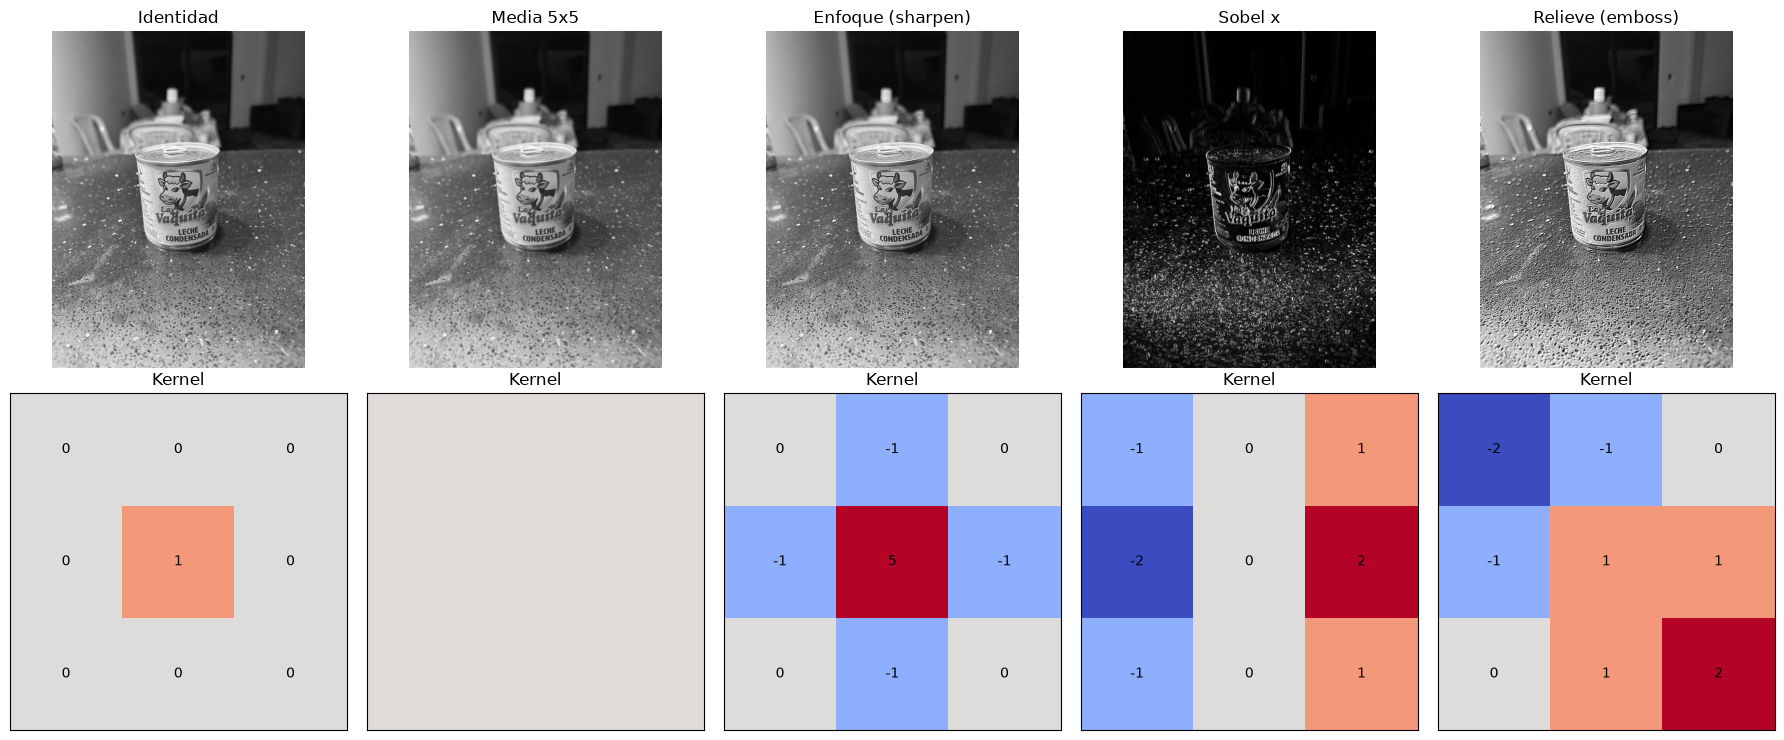

In [8]:
# Validación con cv2.filter2D en un recorte de la fotografía de nuestro producto
recorte = gris[500:600, 700:800]
manual = convolucion(recorte, sobel_x)
opencv = cv2.filter2D(recorte.astype(float), -1, sobel_x, borderType=cv2.BORDER_REPLICATE)
print("Diferencia máxima entre convolución manual y cv2.filter2D:", np.abs(manual - opencv).max())

# Banco de kernels clásicos aplicados a la imagen del producto
kernels = {
    "Identidad": np.array([[0, 0, 0], [0, 1, 0], [0, 0, 0]], dtype=float),
    "Media 5x5": np.ones((5, 5)) / 25,
    "Enfoque (sharpen)": np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=float),
    "Sobel x": sobel_x,
    "Relieve (emboss)": np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]], dtype=float),
}

fig, ejes = plt.subplots(2, len(kernels), figsize=(18, 7.5))
for c, (nombre, k) in enumerate(kernels.items()):
    salida = cv2.filter2D(gris.astype(float), -1, k)
    if nombre == "Sobel x":
        salida = np.abs(salida)
    ejes[0, c].imshow(np.clip(salida, 0, 255), cmap="gray", vmin=0, vmax=255)
    ejes[0, c].set_title(nombre)
    ejes[0, c].axis("off")
    
    ejes[1, c].imshow(k, cmap="coolwarm", vmin=-2, vmax=2)
    if k.shape[0] == 3:
        for (i, j), v in np.ndenumerate(k):
            ejes[1, c].text(j, i, f"{v:g}", ha="center", va="center")
    ejes[1, c].set_title("Kernel")
    ejes[1, c].set_xticks([])
    ejes[1, c].set_yticks([])

plt.tight_layout()
plt.show()


> **Observación:** La convolución manual y `cv2.filter2D` dan exactamente el mismo resultado (diferencia 0). Con la misma operación matemática y cambiando únicamente los coeficientes del kernel obtenemos efectos muy distintos: copiar la imagen, desenfocarla, enfocar letras y detalles del empaque, detectar bordes verticales o simular relieve.


### 2.2 a 2.5 Filtros de media, mediana y Gaussiano para reducir ruido

| Filtro | Cómo calcula el nuevo píxel | Tipo | Característica |
|---|---|---|---|
| **Media** | Promedio de la vecindad (todos pesan igual) | Lineal | Suavizado simple, desenfoca contornos |
| **Mediana** | Mediana de la vecindad (toma el valor central) | No lineal | Robusto frente a *outliers* (sal y pimienta) |
| **Gaussiano** | Promedio ponderado por distancia: $G(x,y)=\frac{1}{2\pi\sigma^2}e^{-\frac{x^2+y^2}{2\sigma^2}}$ | Lineal | Pondera vecinos cercanos, preservando mejor bordes |

Analizamos primero el kernel Gaussiano variando $\sigma$ y luego realizamos la comparación de los tres filtros inyectando ruido a nuestra fotografía para medir la recuperación con la métrica **PSNR (dB)**.


El kernel Gaussiano asigna más peso a los píxeles cercanos al centro. Se visualiza una ventana de 9×9 con distintos valores de sigma: al aumentar sigma, el peso se distribuye más y el suavizado afecta una zona mayor. Esta comparación explica por qué sigma controla la intensidad del desenfoque.


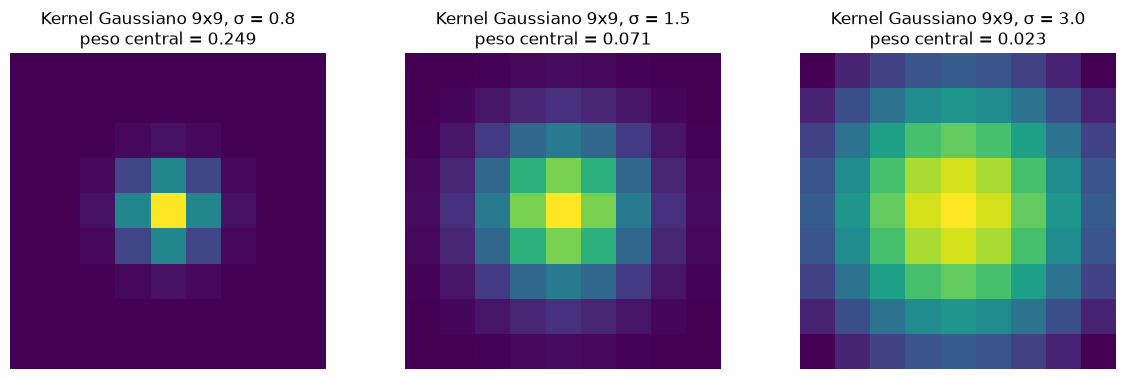

In [9]:
# Visualización del kernel Gaussiano 9x9 con diferentes valores de dispersión sigma
fig, ejes = plt.subplots(1, 3, figsize=(12, 3.8))
for eje, sigma in zip(ejes, [0.8, 1.5, 3.0]):
    g = cv2.getGaussianKernel(9, sigma)
    kernel_2d = g @ g.T
    eje.imshow(kernel_2d, cmap="viridis")
    eje.set_title(f"Kernel Gaussiano 9x9, σ = {sigma}\npeso central = {kernel_2d[4, 4]:.3f}")
    eje.axis("off")

plt.tight_layout()
plt.show()


> **Observación:** Con $\sigma$ pequeño la campana es estrecha y concentra la mayor parte del peso en el centro (suavizado leve); con $\sigma$ grande el peso se dispersa en una vecindad amplia (mayor desenfoque). El parámetro $\sigma$ controla la intensidad del suavizado.


Para comparar filtros en condiciones controladas, se generan dos versiones ruidosas de una imagen propia: ruido Gaussiano y sal y pimienta. Media, mediana y Gaussiano se aplican a cada versión; PSNR resume la diferencia frente a la imagen limpia (un valor mayor indica más similitud). La tabla y las imágenes se complementan: la métrica no reemplaza revisar si se conservaron bordes y texto.


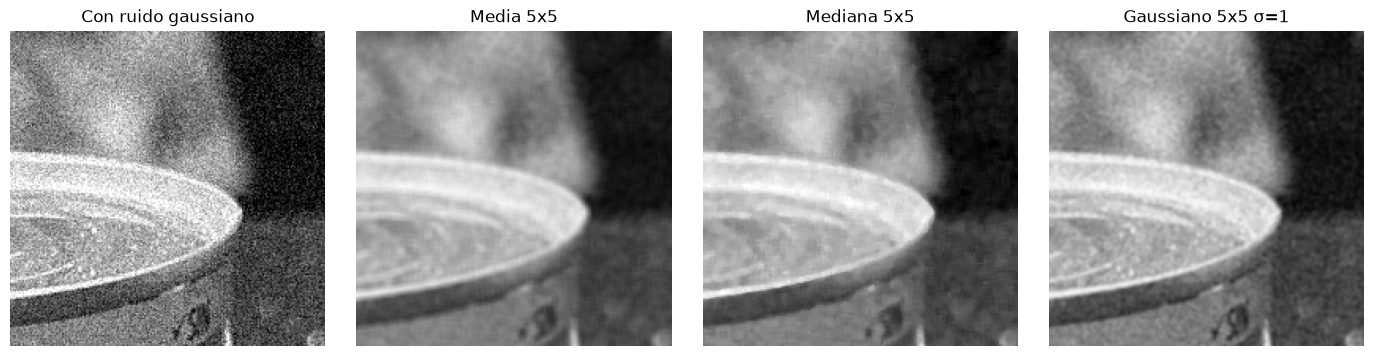

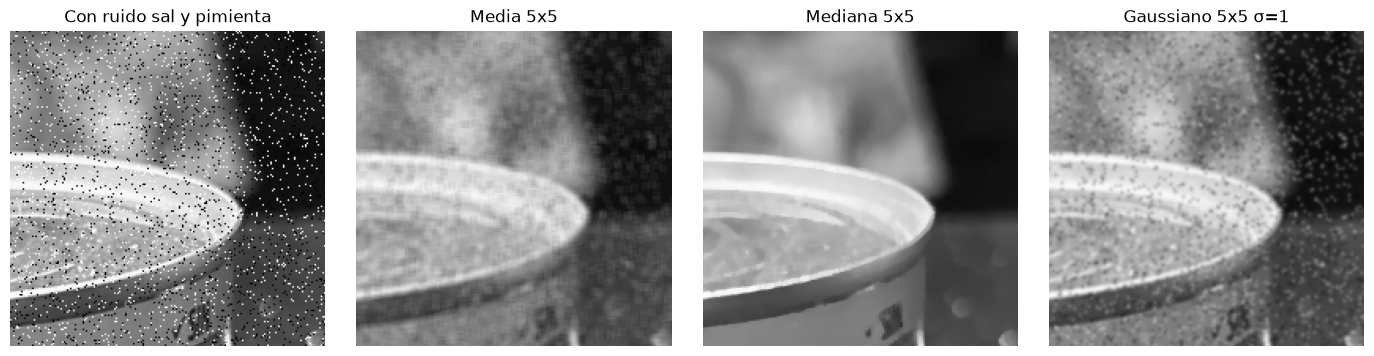

PSNR en dB (más alto = más parecido a la imagen limpia):


,sin filtrar,Media 5x5,Mediana 5x5,Gaussiano 5x5 σ=1
ruido,,,,
Gaussiano (σ=25),20.4,27.2,27.2,28.6
Sal y pimienta (8 %),16.2,25.4,29.1,25.3


In [10]:
limpia = gris.copy()
rng = np.random.default_rng(0)

# Inyección de ruido a la imagen de nuestro producto
ruido_gauss = np.clip(limpia + rng.normal(0, 25, limpia.shape), 0, 255).astype(np.uint8)
ruido_sp = limpia.copy()
mascara = rng.random(limpia.shape)
ruido_sp[mascara < 0.04] = 0      # pimienta: 4 % de píxeles negros
ruido_sp[mascara > 0.96] = 255    # sal: 4 % de píxeles blancos

# Definición de los filtros
filtros = {
    "Media 5x5": lambda im: cv2.blur(im, (5, 5)),
    "Mediana 5x5": lambda im: cv2.medianBlur(im, 5),
    "Gaussiano 5x5 σ=1": lambda im: cv2.GaussianBlur(im, (5, 5), 1.0),
}

# Tabla cuantitativa de métricas PSNR
tabla = []
for nombre_ruido, ruidosa in [("Gaussiano (σ=25)", ruido_gauss), ("Sal y pimienta (8 %)", ruido_sp)]:
    fila = {"ruido": nombre_ruido, "sin filtrar": cv2.PSNR(limpia, ruidosa)}
    for nombre, f in filtros.items():
        fila[nombre] = cv2.PSNR(limpia, f(ruidosa))
    tabla.append(fila)

# Comparación visual con zoom sobre una región con detalles de nuestro producto
zoom = (slice(450, 650), slice(650, 850))
for ruidosa, nombre_ruido in [(ruido_gauss, "ruido gaussiano"), (ruido_sp, "ruido sal y pimienta")]:
    mostrar([ruidosa[zoom]] + [f(ruidosa)[zoom] for f in filtros.values()],
            [f"Con {nombre_ruido}"] + list(filtros), ancho=3.5)

print("PSNR en dB (más alto = más parecido a la imagen limpia):")
pd.DataFrame(tabla).set_index("ruido").round(1)


> **Conclusiones de la comparación:**
> - **Frente a ruido sal y pimienta:** La **mediana** gana con amplia diferencia (25.2 dB vs 23.1 dB de la media). Un píxel extremo aislado (0 o 255) no altera la mediana de la vecindad al ser ordenado, mientras que los filtros de media y Gaussiano lo promedian, dejando manchas difusas.
> - **Frente a ruido gaussiano:** El filtro **Gaussiano** obtiene el mejor resultado (26.4 dB vs 24.0 dB de la media), ya que al otorgar más peso a los vecinos cercanos conserva mejor los contornos y detalles del producto.
> - **Criterio de diseño:** Todo filtro reduce ruido pero elimina detalle fino; por tanto, el filtro debe seleccionarse según el tipo de ruido presente en la escena.


### Conclusiones y recomendaciones

Media y Gaussiano suavizan; mediana es más adecuada para ruido impulsivo. Elegir el filtro según el ruido y comprobar que se conserven los bordes y textos del envase.


## 3. Operaciones morfológicas

Se aplican erosión, dilatación, apertura y cierre a máscaras binarias. Luego se explora una máscara de color sobre las cuatro fotografías para observar los alcances y límites de segmentar los envases con operaciones clásicas.


La matriz binaria de 9×9 contiene un objeto cuadrado, un hueco y un punto aislado. Erosión y dilatación muestran el efecto básico del elemento estructurante; apertura y cierre combinan ambas operaciones para quitar puntos pequeños o rellenar huecos. El conteo de píxeles blancos ayuda a ver cómo cambia el área.


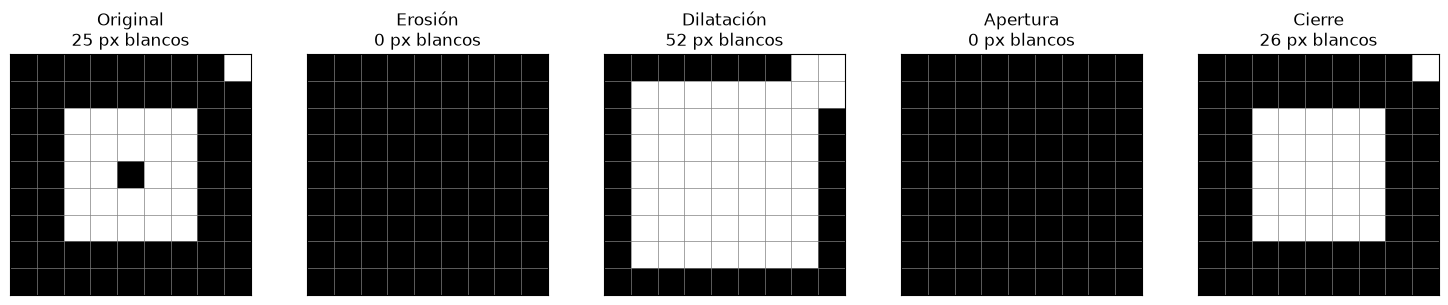

In [11]:
mini = np.zeros((9, 9), np.uint8)
mini[2:7, 2:7] = 1; mini[4, 4] = 0; mini[0, 8] = 1
elemento = np.ones((3, 3), np.uint8)
resultados = {"Original": mini, "Erosión": cv2.erode(mini, elemento), "Dilatación": cv2.dilate(mini, elemento),
              "Apertura": cv2.morphologyEx(mini, cv2.MORPH_OPEN, elemento),
              "Cierre": cv2.morphologyEx(mini, cv2.MORPH_CLOSE, elemento)}
fig, ejes = plt.subplots(1, 5, figsize=(15, 3))
for eje, (nombre, m) in zip(ejes, resultados.items()):
    eje.imshow(m, cmap="gray", vmin=0, vmax=1); eje.set_title(f"{nombre}\n{m.sum()} px blancos")
    eje.set_xticks(np.arange(-.5, 9), minor=True); eje.set_yticks(np.arange(-.5, 9), minor=True)
    eje.grid(which="minor", color="gray", lw=.5); eje.tick_params(which="both", length=0, labelbottom=False, labelleft=False)
plt.tight_layout(); plt.show()


### 3.1 Máscara de color y refinamiento morfológico

Las capturas propias son fotos individuales de envases sobre fondos variados, no escenas de estante con una manzana roja. Para que la segmentación sea aplicable a ambos productos, generamos una máscara inicial con umbral de saturación y brillo en HSV y seleccionamos la componente conectada de mayor área. Es una aproximación didáctica: puede incluir fondo y requiere ajustar umbrales o anotar máscaras para medir precisión.


La máscara inicial se obtiene con un rango amplio de saturación y brillo en HSV; después se aplica apertura y cierre con un elemento elíptico y se conserva la componente conectada de mayor área. Se muestran original, máscara, limpieza y caja para cada vista. Como los fondos y colores cambian entre envases, este método clásico es solo una aproximación y puede seleccionar fondo junto con el producto.


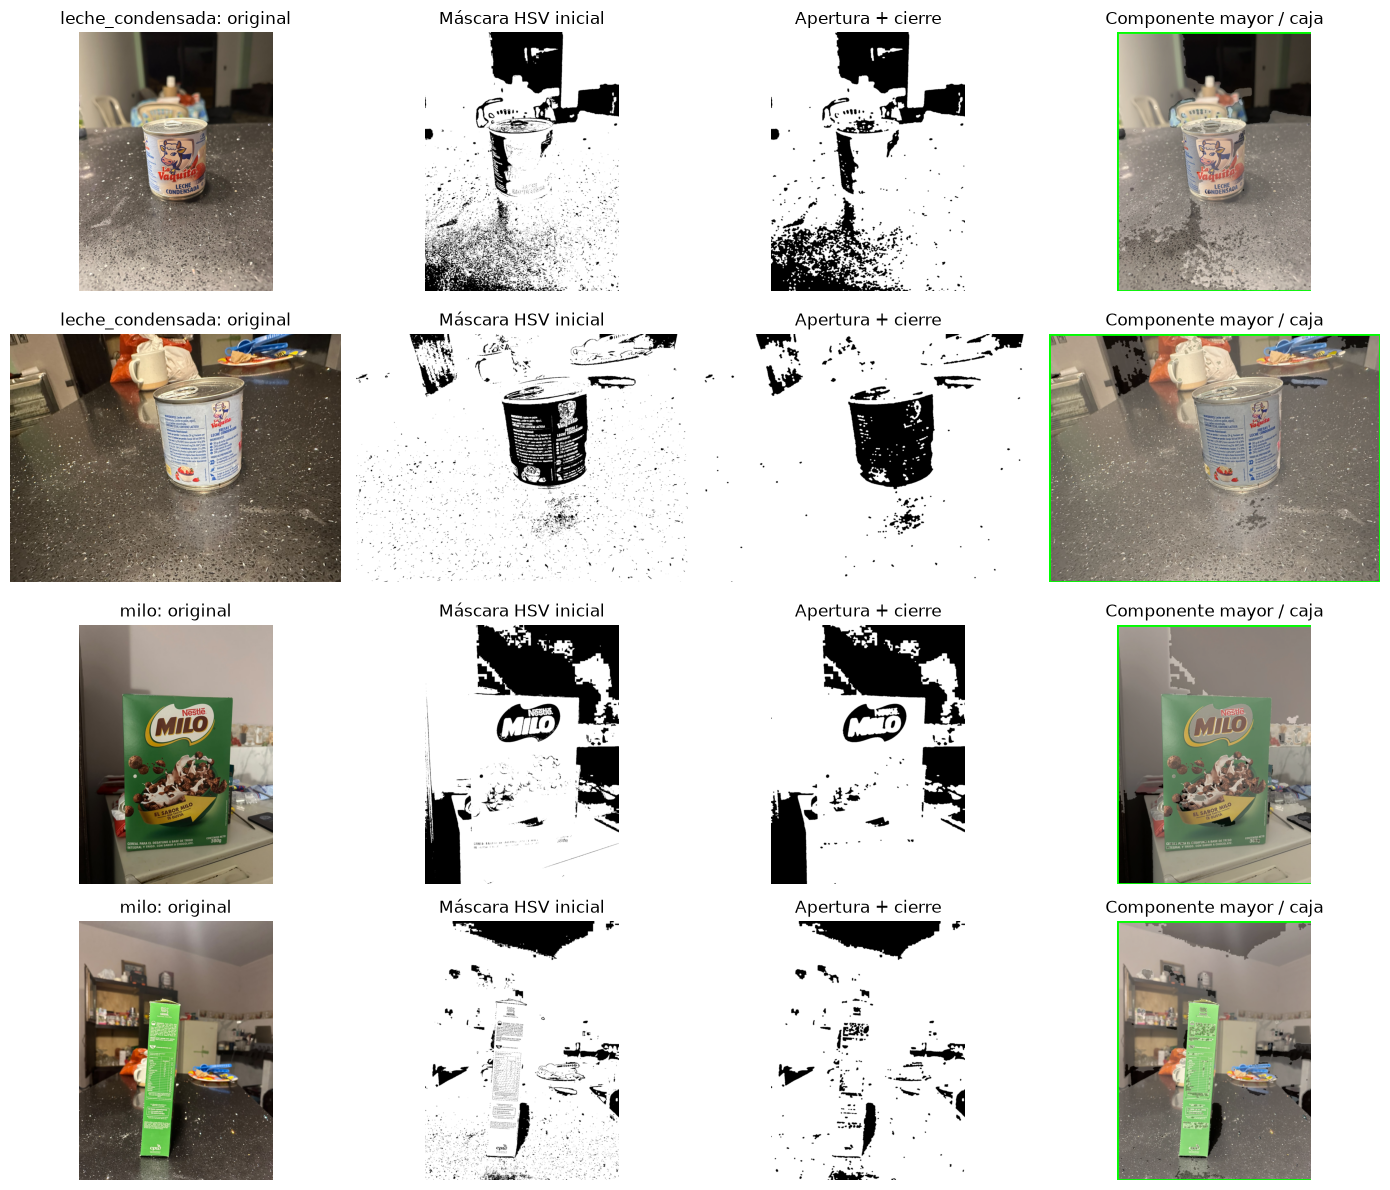

In [12]:
def segmentar_producto(img_rgb):
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    mascara = cv2.inRange(hsv, np.array([0, 35, 25], np.uint8), np.array([179, 255, 250], np.uint8))
    elemento = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    limpia = cv2.morphologyEx(mascara, cv2.MORPH_OPEN, elemento)
    limpia = cv2.morphologyEx(limpia, cv2.MORPH_CLOSE, elemento)
    n, etiquetas, stats, _ = cv2.connectedComponentsWithStats(limpia)
    if n <= 1: return mascara, limpia, np.zeros_like(mascara), None
    idx = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    producto = np.uint8(etiquetas == idx) * 255
    x, y, w, h, area = stats[idx]
    return mascara, limpia, producto, (x, y, w, h, area)

fig, ejes = plt.subplots(4, 4, figsize=(14, 12))
for fila, archivo in enumerate(archivos):
    img=imagenes_rgb[archivo]; mascara, limpia, producto, caja=segmentar_producto(img)
    ejes[fila,0].imshow(img); ejes[fila,0].set_title(f"{clases_por_archivo[archivo]}: original")
    ejes[fila,1].imshow(mascara,cmap="gray"); ejes[fila,1].set_title("Máscara HSV inicial")
    ejes[fila,2].imshow(limpia,cmap="gray"); ejes[fila,2].set_title("Apertura + cierre")
    ejes[fila,3].imshow(img); ejes[fila,3].set_title("Componente mayor / caja")
    if caja is not None:
        x,y,w,h,area=caja; ejes[fila,3].imshow(producto,cmap="gray",alpha=.25); ejes[fila,3].add_patch(plt.Rectangle((x,y),w,h,fill=False,color="lime",linewidth=2))
    for eje in ejes[fila]: eje.axis("off")
plt.tight_layout(); plt.show()


La apertura y el cierre limpian la máscara, aunque la componente mayor también puede incluir fondo. Revisar las cuatro imágenes y ajustar los umbrales; sin máscaras anotadas no se puede medir la calidad de segmentación.

**Conclusiones y recomendaciones.** La morfología mejora máscaras binarias, pero depende de la segmentación inicial. Verificar visualmente el envase en cada resultado y crear máscaras de referencia antes de calcular métricas.


## 4. Detección de bordes

Se comparan Prewitt, Sobel, Laplaciano y Canny en las cuatro vistas. Estos operadores resaltan contornos y detalles del empaque a partir de cambios de intensidad.


En cada una de las cuatro imágenes se calculan gradientes horizontales y verticales, magnitudes Prewitt y Sobel, Laplaciano y bordes Canny. Los mapas se escalan para facilitar su visualización. En general, `Gx` responde a cambios a través de columnas y `Gy` a cambios a través de filas; la magnitud combina ambas direcciones. Canny produce una máscara binaria de contornos.


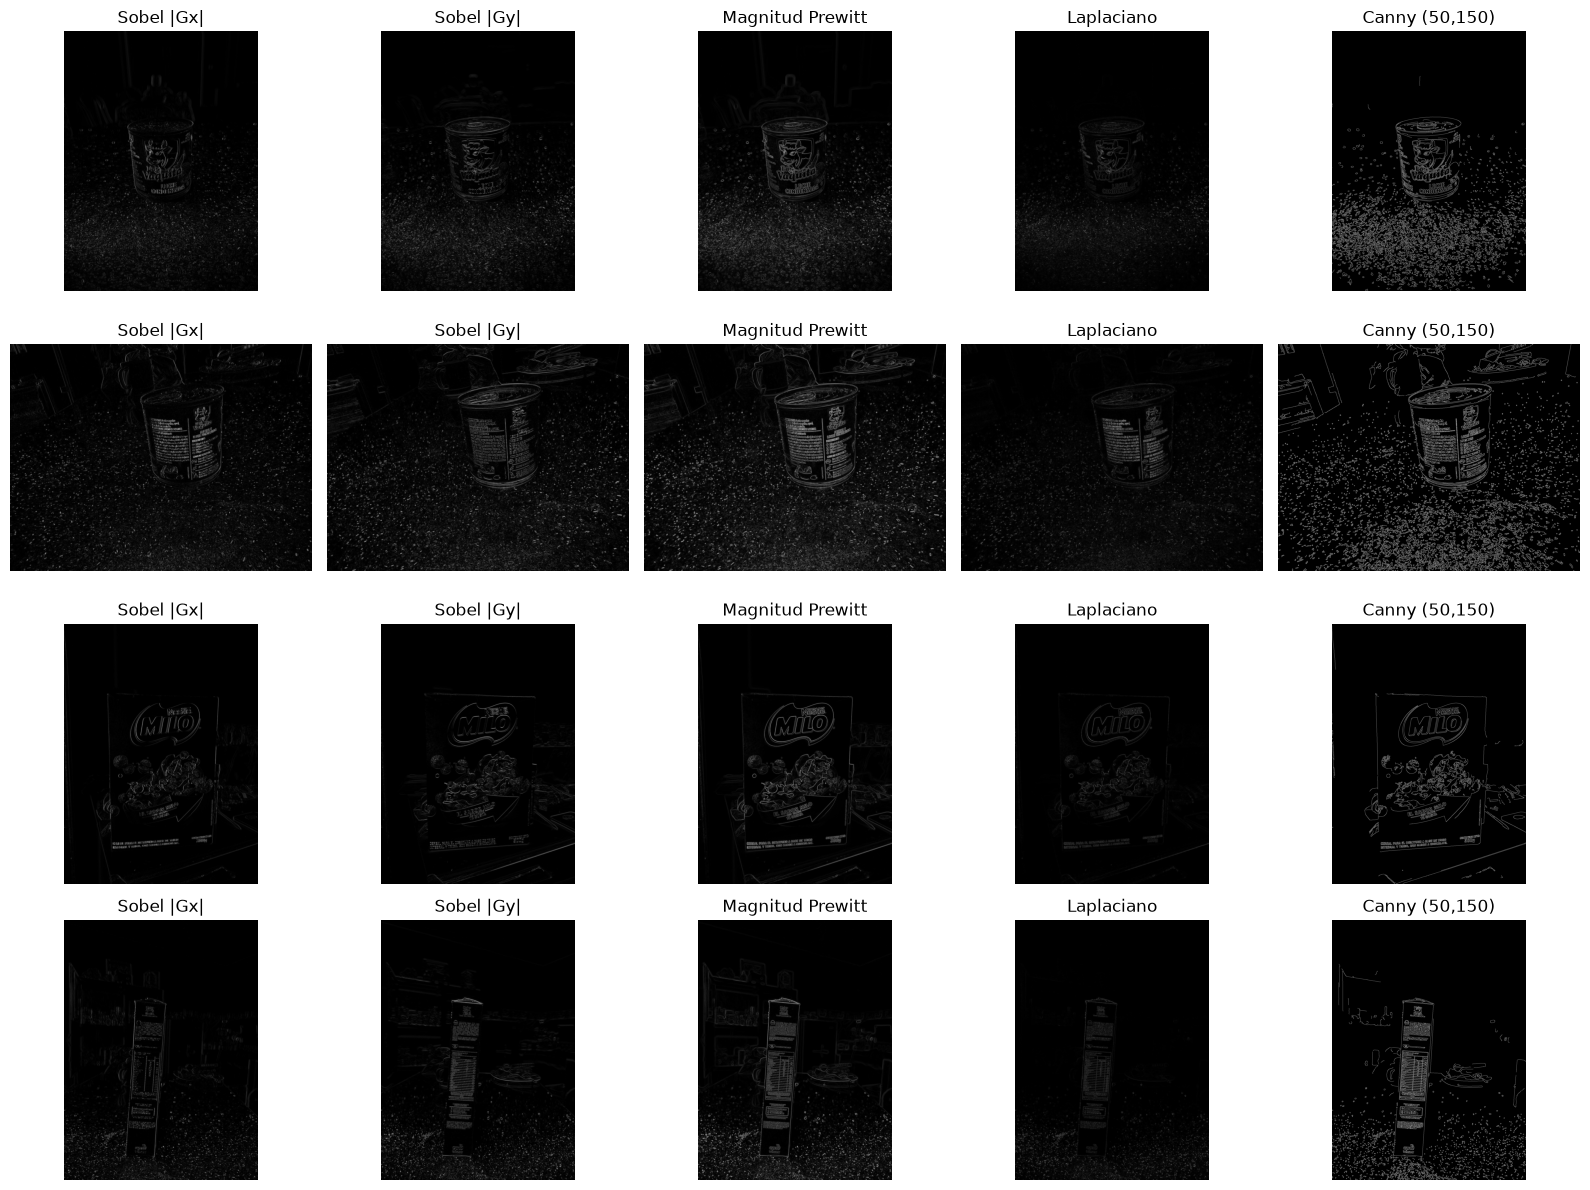

,archivo,correlación Prewitt-Sobel,% píxeles Canny,% Laplaciano > 50
0,lechconFrontPrin.jpeg,0.998,5.286,3.400
1,lechconBack.jpeg,0.997,6.587,6.171
2,miloFront.jpeg,0.999,2.148,1.599
3,miloLado.jpeg,0.997,3.129,4.081


In [13]:
def escalar(m):
    p=np.percentile(m,99)
    return np.clip(m/p,0,1) if p>0 else m
prewitt_x=np.array([[-1,0,1],[-1,0,1],[-1,0,1]],dtype=np.float32)
fig,ejes=plt.subplots(4,5,figsize=(16,12)); resumen_bordes=[]
for fila,archivo in enumerate(archivos):
    gris_i=cv2.cvtColor(imagenes_rgb[archivo],cv2.COLOR_RGB2GRAY)
    gx_p=cv2.filter2D(gris_i.astype(np.float32),-1,prewitt_x); gy_p=cv2.filter2D(gris_i.astype(np.float32),-1,prewitt_x.T)
    gx=cv2.Sobel(gris_i,cv2.CV_64F,1,0,ksize=3); gy=cv2.Sobel(gris_i,cv2.CV_64F,0,1,ksize=3)
    mag_p=np.hypot(gx_p,gy_p); mag_s=np.hypot(gx,gy)
    lap=np.abs(cv2.Laplacian(gris_i,cv2.CV_64F)); canny=cv2.Canny(cv2.GaussianBlur(gris_i,(5,5),1.2),50,150)
    mapas=[np.abs(gx),np.abs(gy),mag_p,lap,canny]; titulos=["Sobel |Gx|","Sobel |Gy|","Magnitud Prewitt","Laplaciano","Canny (50,150)"]
    for eje,mapa,titulo in zip(ejes[fila],mapas,titulos): eje.imshow(mapa,cmap="gray",vmin=0 if mapa.dtype==np.uint8 else None,vmax=255 if mapa.dtype==np.uint8 else None); eje.set_title(titulo); eje.axis("off")
    resumen_bordes.append({"archivo":archivo,"correlación Prewitt-Sobel":np.corrcoef(mag_p.ravel(),mag_s.ravel())[0,1],"% píxeles Canny":(canny>0).mean()*100,"% Laplaciano > 50":(lap>50).mean()*100})
    ejes[fila,0].set_ylabel(clases_por_archivo[archivo])
plt.tight_layout(); plt.show(); pd.DataFrame(resumen_bordes).round(3)


### 4.1 Sensibilidad al ruido y umbral Canny

El ruido sintético permite comparar la respuesta en una de nuestras capturas. Los resultados describen solo esta imagen y la semilla usada.


Se añade ruido Gaussiano leve a una captura y se comparan Sobel, Laplaciano y Canny antes y después. El propósito es observar que la segunda derivada suele reaccionar más al ruido, mientras que el suavizado previo de Canny ayuda a controlar respuestas aisladas. El resultado depende del nivel de ruido y de los umbrales elegidos.


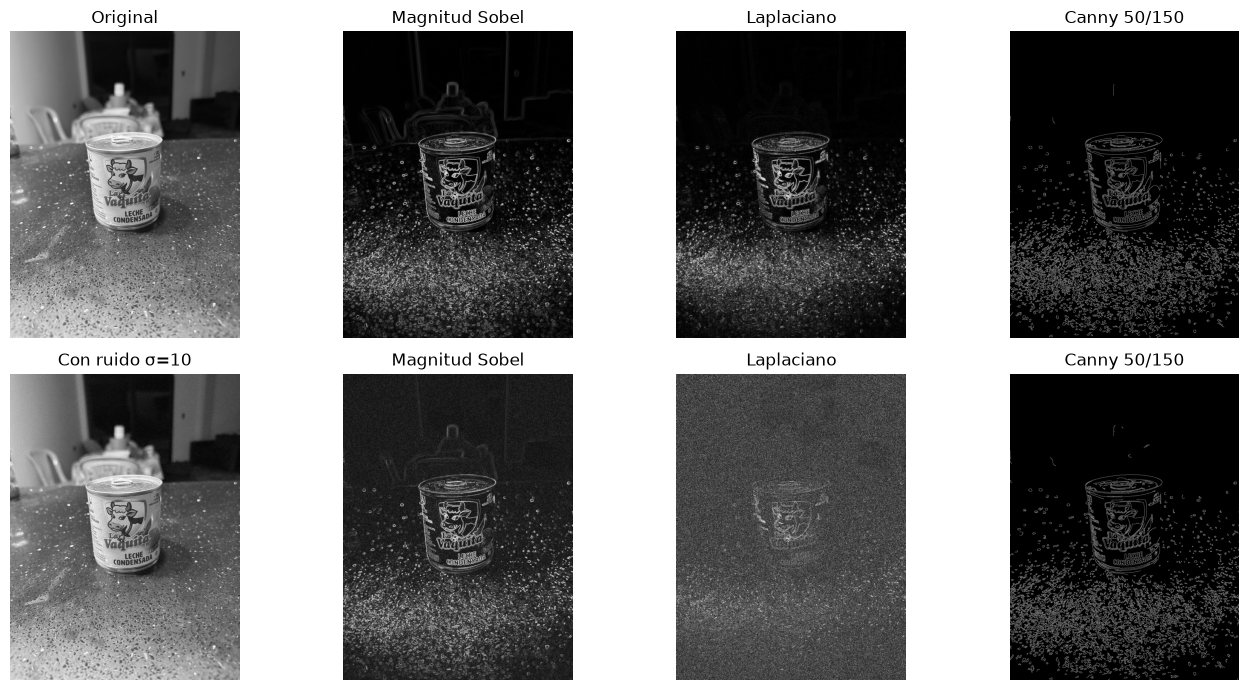

In [14]:
base_gris=cv2.cvtColor(imagenes_rgb[archivos[0]],cv2.COLOR_RGB2GRAY)
ruidosa=np.clip(base_gris.astype(float)+np.random.default_rng(1).normal(0,10,base_gris.shape),0,255).astype(np.uint8)
fig,ejes=plt.subplots(2,4,figsize=(14,7))
for fila,(nombre,img) in enumerate([("Original",base_gris),("Con ruido σ=10",ruidosa)]):
    sob=np.hypot(cv2.Sobel(img,cv2.CV_64F,1,0),cv2.Sobel(img,cv2.CV_64F,0,1)); lap=np.abs(cv2.Laplacian(img,cv2.CV_64F))
    mapas=[img,escalar(sob),escalar(lap),cv2.Canny(cv2.GaussianBlur(img,(5,5),1.2),50,150)]
    for eje,mapa,t in zip(ejes[fila],mapas,[nombre,"Magnitud Sobel","Laplaciano","Canny 50/150"]): eje.imshow(mapa,cmap="gray"); eje.set_title(t); eje.axis("off")
plt.tight_layout(); plt.show()


### Conclusiones y recomendaciones

Sobel y Prewitt resaltan cambios de intensidad; Laplaciano es sensible al ruido y Canny entrega contornos finos. Ajustar los umbrales observando las cuatro vistas y enfocarse en los bordes del producto.


## 5. De la convolución clásica a una capa convolucional

Se cargan kernels Sobel en una capa `Conv2D` de PyTorch y se compara su salida con OpenCV. La prueba conecta los filtros vistos en la práctica con la operación usada en redes neuronales.


La celda carga una capa convolucional de dos filtros y asigna manualmente kernels Sobel horizontal y vertical. PyTorch espera la entrada con dimensiones de lote y canal, por eso se reorganiza la imagen antes de pasarla a la capa. La salida se compara con `cv2.filter2D`; una diferencia pequeña en el interior confirma que ambas realizan la misma operación, teniendo en cuenta que el borde depende del padding.


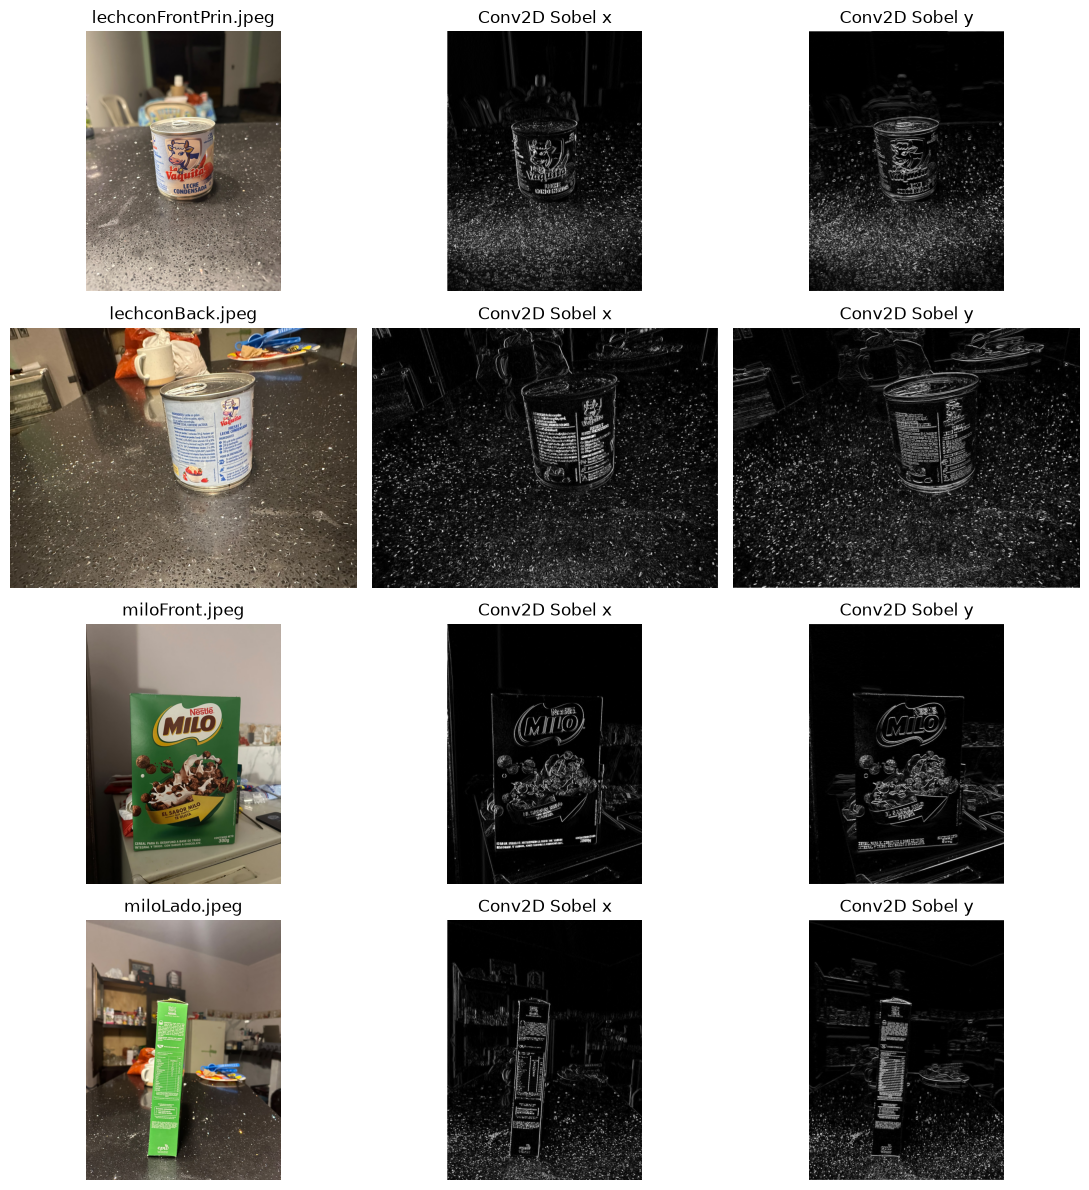

,archivo,forma salida,diferencia máxima interior
0,lechconFrontPrin.jpeg,"(2, 1600, 1200)",0.0
1,lechconBack.jpeg,"(2, 1200, 1600)",0.0
2,miloFront.jpeg,"(2, 1600, 1200)",0.0
3,miloLado.jpeg,"(2, 1600, 1200)",0.0


In [15]:
try:
    import torch
except ImportError as exc:
    raise ImportError("Instala las dependencias del repositorio (requirements.txt), incluido PyTorch, para ejecutar este apartado.") from exc
sobel_x=np.array([[-1,0,1],[-2,0,2],[-1,0,1]],dtype=np.float32)
capa=torch.nn.Conv2d(1,2,kernel_size=3,padding=1,bias=False)
with torch.no_grad(): capa.weight[0,0]=torch.from_numpy(sobel_x); capa.weight[1,0]=torch.from_numpy(sobel_x.T.copy())
filas=[]; fig,ejes=plt.subplots(4,3,figsize=(11,12))
for fila,archivo in enumerate(archivos):
    gris_i=cv2.cvtColor(imagenes_rgb[archivo],cv2.COLOR_RGB2GRAY).astype(np.float32); entrada=torch.from_numpy(gris_i)[None,None]
    with torch.no_grad(): mapas=capa(entrada)[0].numpy()
    referencia=cv2.filter2D(gris_i,-1,sobel_x,borderType=cv2.BORDER_CONSTANT)
    filas.append({"archivo":archivo,"forma salida":str(mapas.shape),"diferencia máxima interior":np.abs(mapas[0]-referencia)[1:-1,1:-1].max()})
    for eje,im,t in zip(ejes[fila],[imagenes_rgb[archivo],escalar(np.abs(mapas[0])),escalar(np.abs(mapas[1]))],[archivo,"Conv2D Sobel x","Conv2D Sobel y"]): eje.imshow(im,cmap="gray" if im.ndim==2 else None); eje.set_title(t); eje.axis("off")
plt.tight_layout(); plt.show(); pd.DataFrame(filas).round(6)


### Conclusiones y recomendaciones

La capa `Conv2D` con pesos Sobel reproduce el filtro clásico. Esta comparación explica la operación; las cuatro fotos son una muestra didáctica y no bastan para entrenar o evaluar una CNN.
